In [ ]:
# Project 1: Financial Performance Analysis
# Analyzing Growth, Profitability and Financial Risk
# FY2021–FY2025

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Project 1 setup successful!")

Project 1 setup successful!


In [ ]:
companies = {
    "Apple": "AAPL",
    "Microsoft": "MSFT",
    "Alphabet": "GOOGL",
    "Amazon": "AMZN",
    "Meta": "META",
    "NVIDIA": "NVDA",
    "Adobe": "ADBE",
    "Cisco": "CSCO",
    "IBM": "IBM",
    "Oracle": "ORCL"
}

print("Companies in the project:")
for company, ticker in companies.items():
    print(company, "-", ticker)

print("\nTotal companies:", len(companies))

Companies in the project:
Apple - AAPL
Microsoft - MSFT
Alphabet - GOOGL
Amazon - AMZN
Meta - META
NVIDIA - NVDA
Adobe - ADBE
Cisco - CSCO
IBM - IBM
Oracle - ORCL

Total companies: 10


In [ ]:
years = [2021, 2022, 2023, 2024, 2025]

print("Financial years:", years)
print("Number of years:", len(years))

Financial years: [2021, 2022, 2023, 2024, 2025]
Number of years: 5


In [ ]:
financial_columns = [
    "company",
    "ticker",
    "fiscal_year",
    "revenue",
    "net_income",
    "total_assets",
    "total_liabilities"
]

print("Raw financial variables:")
for column in financial_columns:
    print("-", column)

Raw financial variables:
- company
- ticker
- fiscal_year
- revenue
- net_income
- total_assets
- total_liabilities


In [ ]:
SEC_HEADERS = {
    "User-Agent": "Financial Analytics Student vanshikapateltirumani@gmail.com"
}

SEC_BASE_URL = "https://data.sec.gov/api/xbrl/companyfacts"

print("SEC connection settings created successfully!")

SEC connection settings created successfully!


In [ ]:
ciks = {
    "Apple": "0000320193",
    "Microsoft": "0000789019",
    "Alphabet": "0001652044",
    "Amazon": "0001018724",
    "Meta": "0001326801",
    "NVIDIA": "0001045810",
    "Adobe": "0000796343",
    "Cisco": "0000858877",
    "IBM": "0000051143",
    "Oracle": "0001341439"
}

print("SEC CIKs loaded:")
for company, cik in ciks.items():
    print(company, "-", cik)

print("\nTotal CIKs:", len(ciks))

SEC CIKs loaded:
Apple - 0000320193
Microsoft - 0000789019
Alphabet - 0001652044
Amazon - 0001018724
Meta - 0001326801
NVIDIA - 0001045810
Adobe - 0000796343
Cisco - 0000858877
IBM - 0000051143
Oracle - 0001341439

Total CIKs: 10


In [ ]:
# Step 1: Download SEC company facts for all 10 companies

import pandas as pd
import numpy as np
import requests
import time

SEC_BASE_URL = "https://data.sec.gov/api/xbrl/companyfacts"

SEC_HEADERS = {
    "User-Agent": "Financial Analytics Student your_email@gmail.com"
}

sec_data = {}

for company, cik in ciks.items():

    print(f"Downloading {company}...")

    url = f"{SEC_BASE_URL}/CIK{cik}.json"

    response = requests.get(
        url,
        headers=SEC_HEADERS,
        timeout=30
    )

    if response.status_code == 200:
        sec_data[company] = response.json()
        print("✓ Success")
    else:
        print(f"✗ Failed - HTTP {response.status_code}")

    time.sleep(0.3)

print("\n" + "=" * 60)
print("SEC DATA DOWNLOAD COMPLETE")
print("=" * 60)
print("Companies loaded:", len(sec_data))

✓ Success
✓ Success
✓ Success
✓ Success
✓ Success
✓ Success
✓ Success
✓ Success
✓ Success
✓ Success

SEC DATA DOWNLOAD COMPLETE
Companies loaded: 10


In [ ]:
# Step 2: Check which standard revenue concepts are available

revenue_candidates = [
    "RevenueFromContractWithCustomerExcludingAssessedTax",
    "Revenues",
    "SalesRevenueNet"
]

revenue_concepts = {}

for company, facts in sec_data.items():

    gaap = facts["facts"].get("us-gaap", {})

    available = [
        concept
        for concept in revenue_candidates
        if concept in gaap
    ]

    revenue_concepts[company] = available

    print(f"{company}: {available}")

print("\nRevenue concept check complete.")

Apple: ['RevenueFromContractWithCustomerExcludingAssessedTax', 'Revenues', 'SalesRevenueNet']
Microsoft: ['RevenueFromContractWithCustomerExcludingAssessedTax', 'Revenues', 'SalesRevenueNet']
Alphabet: ['RevenueFromContractWithCustomerExcludingAssessedTax', 'Revenues']
Amazon: ['RevenueFromContractWithCustomerExcludingAssessedTax', 'SalesRevenueNet']
Meta: ['RevenueFromContractWithCustomerExcludingAssessedTax', 'Revenues']
NVIDIA: ['RevenueFromContractWithCustomerExcludingAssessedTax', 'Revenues']
Adobe: ['Revenues']
Cisco: ['RevenueFromContractWithCustomerExcludingAssessedTax', 'Revenues', 'SalesRevenueNet']
IBM: ['Revenues']
Oracle: ['RevenueFromContractWithCustomerExcludingAssessedTax', 'Revenues', 'SalesRevenueNet']

Revenue concept check complete.


In [ ]:
# Step 3: Extract annual revenue for FY2021-FY2025

revenue_data = {}

for company, facts in sec_data.items():

    gaap = facts["facts"].get("us-gaap", {})

    company_records = []

    for concept in revenue_candidates:

        if concept not in gaap:
            continue

        units = gaap[concept].get("units", {})

        if "USD" not in units:
            continue

        df = pd.DataFrame(units["USD"]).copy()

        # Keep annual 10-K / 10-K/A records
        df = df[
            df["form"].isin(["10-K", "10-K/A"])
        ].copy()

        # Convert dates
        df["start"] = pd.to_datetime(
            df["start"],
            errors="coerce"
        )

        df["end"] = pd.to_datetime(
            df["end"],
            errors="coerce"
        )

        # Keep only complete annual periods
        df["days"] = (
            df["end"] - df["start"]
        ).dt.days

        df = df[
            df["days"].between(300, 400)
        ].copy()

        # Fiscal year = year in which the reporting period ended
        df["fiscal_year"] = df["end"].dt.year

        # Keep FY2021-FY2025
        df = df[
            df["fiscal_year"].between(2021, 2025)
        ].copy()

        # Remember which SEC concept supplied the value
        df["concept"] = concept

        company_records.append(
            df[
                [
                    "fiscal_year",
                    "start",
                    "end",
                    "val",
                    "filed",
                    "concept"
                ]
            ]
        )

    # Combine all available revenue concepts
    if company_records:

        combined = pd.concat(
            company_records,
            ignore_index=True
        )

        # Revenue concept priority:
        # 1. RevenueFromContractWithCustomerExcludingAssessedTax
        # 2. Revenues
        # 3. SalesRevenueNet
        combined["concept_priority"] = (
            combined["concept"]
            .map({
                "RevenueFromContractWithCustomerExcludingAssessedTax": 1,
                "Revenues": 2,
                "SalesRevenueNet": 3
            })
        )

        # Prefer the highest-priority concept.
        # If the same concept appears multiple times,
        # keep the latest filed version.
        combined = combined.sort_values(
            [
                "fiscal_year",
                "concept_priority",
                "filed"
            ]
        )

        combined = (
            combined
            .drop_duplicates(
                "fiscal_year",
                keep="last"
            )
            .sort_values("fiscal_year")
        )

        # Add company information
        combined["company"] = company
        combined["ticker"] = [
            ticker
            for name, ticker in companies.items()
            if name == company
        ][0]

        revenue_data[company] = combined[
            [
                "company",
                "ticker",
                "fiscal_year",
                "start",
                "end",
                "val",
                "concept"
            ]
        ].reset_index(drop=True)

# ---------------------------------------------------------
# Verification
# ---------------------------------------------------------

print("=" * 70)
print("REVENUE EXTRACTION RESULTS")
print("=" * 70)

for company, df in revenue_data.items():

    print(
        f"{company}: {len(df)} years -> "
        f"{df['fiscal_year'].astype(int).tolist()}"
    )

total_observations = sum(
    len(df) for df in revenue_data.values()
)

print("\n" + "=" * 70)
print("TOTAL REVENUE OBSERVATIONS:", total_observations)
print("EXPECTED:", len(companies) * 5)
print("=" * 70)

REVENUE EXTRACTION RESULTS
Apple: 5 years -> [2021, 2022, 2023, 2024, 2025]
Microsoft: 5 years -> [2021, 2022, 2023, 2024, 2025]
Alphabet: 5 years -> [2021, 2022, 2023, 2024, 2025]
Amazon: 5 years -> [2021, 2022, 2023, 2024, 2025]
Meta: 5 years -> [2021, 2022, 2023, 2024, 2025]
NVIDIA: 5 years -> [2021, 2022, 2023, 2024, 2025]
Adobe: 5 years -> [2021, 2022, 2023, 2024, 2025]
Cisco: 5 years -> [2021, 2022, 2023, 2024, 2025]
IBM: 5 years -> [2021, 2022, 2023, 2024, 2025]
Oracle: 5 years -> [2021, 2022, 2023, 2024, 2025]

TOTAL REVENUE OBSERVATIONS: 50
EXPECTED: 50


In [ ]:
# Step 4: Combine all company revenue data into one table

revenue_df = pd.concat(
    revenue_data.values(),
    ignore_index=True
)

# Convert SEC revenue values from dollars to billions
revenue_df["revenue"] = revenue_df["val"] / 1_000_000_000

# Keep only the columns we need for the project
revenue_df = revenue_df[
    [
        "company",
        "ticker",
        "fiscal_year",
        "start",
        "end",
        "revenue",
        "concept"
    ]
].sort_values(
    ["company", "fiscal_year"]
).reset_index(drop=True)

print("Revenue dataset shape:", revenue_df.shape)

print("\nFirst 10 rows:")
display(revenue_df.head(10))

print("\nMissing revenue values:")
print(revenue_df["revenue"].isna().sum())

Revenue dataset shape: (50, 7)

First 10 rows:


,company,ticker,fiscal_year,start,end,revenue,concept
0,Adobe,ADBE,2021,2020-11-28,2021-12-03,15.785,Revenues
1,Adobe,ADBE,2022,2021-12-04,2022-12-02,17.606,Revenues
2,Adobe,ADBE,2023,2022-12-03,2023-12-01,19.409,Revenues
3,Adobe,ADBE,2024,2023-12-02,2024-11-29,21.505,Revenues
4,Adobe,ADBE,2025,2024-11-30,2025-11-28,23.769,Revenues
5,Alphabet,GOOGL,2021,2021-01-01,2021-12-31,257.637,Revenues
6,Alphabet,GOOGL,2022,2022-01-01,2022-12-31,282.836,RevenueFromContractWithCustomerExcludingAssess...
7,Alphabet,GOOGL,2023,2023-01-01,2023-12-31,307.394,Revenues
8,Alphabet,GOOGL,2024,2024-01-01,2024-12-31,350.018,Revenues
9,Alphabet,GOOGL,2025,2025-01-01,2025-12-31,402.836,Revenues



Missing revenue values:
0


In [ ]:
# Step 5: Check which standard Net Income concepts are available

net_income_candidates = [
    "ProfitLoss",
    "NetIncomeLoss",
    "ProfitLossAttributableToParent"
]

net_income_concepts = {}

for company, facts in sec_data.items():

    gaap = facts["facts"].get("us-gaap", {})

    available = [
        concept
        for concept in net_income_candidates
        if concept in gaap
    ]

    net_income_concepts[company] = available

    print(f"{company}: {available}")

print("\nNet income concept check complete.")

Apple: ['NetIncomeLoss']
Microsoft: ['NetIncomeLoss']
Alphabet: ['NetIncomeLoss']
Amazon: ['NetIncomeLoss']
Meta: ['NetIncomeLoss']
NVIDIA: ['NetIncomeLoss']
Adobe: ['NetIncomeLoss']
Cisco: ['ProfitLoss', 'NetIncomeLoss']
IBM: ['ProfitLoss', 'NetIncomeLoss']
Oracle: ['ProfitLoss', 'NetIncomeLoss']

Net income concept check complete.


In [ ]:
# Step 6: Display available Net Income concepts

for company, concepts in net_income_concepts.items():
    print(f"{company}: {concepts}")

print("\nNet income concept check complete.")

Apple: ['NetIncomeLoss']
Microsoft: ['NetIncomeLoss']
Alphabet: ['NetIncomeLoss']
Amazon: ['NetIncomeLoss']
Meta: ['NetIncomeLoss']
NVIDIA: ['NetIncomeLoss']
Adobe: ['NetIncomeLoss']
Cisco: ['ProfitLoss', 'NetIncomeLoss']
IBM: ['ProfitLoss', 'NetIncomeLoss']
Oracle: ['ProfitLoss', 'NetIncomeLoss']

Net income concept check complete.


In [ ]:
# Step 7: Extract annual Net Income for FY2021-FY2025

net_income_data = {}

for company, facts in sec_data.items():

    gaap = facts["facts"].get("us-gaap", {})
    company_records = []

    for concept in net_income_candidates:

        if concept not in gaap:
            continue

        units = gaap[concept].get("units", {})

        if "USD" not in units:
            continue

        df = pd.DataFrame(units["USD"]).copy()

        # Keep annual 10-K / 10-K/A records
        df = df[
            df["form"].isin(["10-K", "10-K/A"])
        ].copy()

        # Convert dates
        df["start"] = pd.to_datetime(
            df["start"],
            errors="coerce"
        )

        df["end"] = pd.to_datetime(
            df["end"],
            errors="coerce"
        )

        # Keep complete annual reporting periods
        df["days"] = (
            df["end"] - df["start"]
        ).dt.days

        df = df[
            df["days"].between(300, 400)
        ].copy()

        # Fiscal year = year in which reporting period ended
        df["fiscal_year"] = df["end"].dt.year

        # Keep FY2021-FY2025
        df = df[
            df["fiscal_year"].between(2021, 2025)
        ].copy()

        df["concept"] = concept

        company_records.append(
            df[
                [
                    "fiscal_year",
                    "start",
                    "end",
                    "val",
                    "filed",
                    "concept"
                ]
            ]
        )

    if company_records:

        combined = pd.concat(
            company_records,
            ignore_index=True
        )

        # Concept priority
        combined["concept_priority"] = (
            combined["concept"]
            .map({
                "ProfitLoss": 1,
                "NetIncomeLoss": 2,
                "ProfitLossAttributableToParent": 3
            })
        )

        # Prefer the primary concept and latest filing
        combined = combined.sort_values(
            [
                "fiscal_year",
                "concept_priority",
                "filed"
            ]
        )

        combined = (
            combined
            .drop_duplicates(
                "fiscal_year",
                keep="last"
            )
            .sort_values("fiscal_year")
        )

        combined["company"] = company
        combined["ticker"] = companies[company]

        net_income_data[company] = combined[
            [
                "company",
                "ticker",
                "fiscal_year",
                "start",
                "end",
                "val",
                "concept"
            ]
        ].reset_index(drop=True)

# ---------------------------------------------------------
# Verification
# ---------------------------------------------------------

print("=" * 70)
print("NET INCOME EXTRACTION RESULTS")
print("=" * 70)

for company, df in net_income_data.items():

    print(
        f"{company}: {len(df)} years -> "
        f"{df['fiscal_year'].astype(int).tolist()}"
    )

total_observations = sum(
    len(df) for df in net_income_data.values()
)

print("\n" + "=" * 70)
print("TOTAL NET INCOME OBSERVATIONS:", total_observations)
print("EXPECTED:", len(companies) * 5)
print("=" * 70)

NET INCOME EXTRACTION RESULTS
Apple: 5 years -> [2021, 2022, 2023, 2024, 2025]
Microsoft: 5 years -> [2021, 2022, 2023, 2024, 2025]
Alphabet: 5 years -> [2021, 2022, 2023, 2024, 2025]
Amazon: 5 years -> [2021, 2022, 2023, 2024, 2025]
Meta: 5 years -> [2021, 2022, 2023, 2024, 2025]
NVIDIA: 5 years -> [2021, 2022, 2023, 2024, 2025]
Adobe: 5 years -> [2021, 2022, 2023, 2024, 2025]
Cisco: 5 years -> [2021, 2022, 2023, 2024, 2025]
IBM: 5 years -> [2021, 2022, 2023, 2024, 2025]
Oracle: 5 years -> [2021, 2022, 2023, 2024, 2025]

TOTAL NET INCOME OBSERVATIONS: 50
EXPECTED: 50


In [ ]:
# Step 8: Check which standard Total Assets concepts are available

assets_candidates = [
    "Assets"
]

assets_concepts = {}

for company, facts in sec_data.items():

    gaap = facts["facts"].get("us-gaap", {})

    available = [
        concept
        for concept in assets_candidates
        if concept in gaap
    ]

    assets_concepts[company] = available

    print(f"{company}: {available}")

print("\nTotal assets concept check complete.")

Apple: ['Assets']
Microsoft: ['Assets']
Alphabet: ['Assets']
Amazon: ['Assets']
Meta: ['Assets']
NVIDIA: ['Assets']
Adobe: ['Assets']
Cisco: ['Assets']
IBM: ['Assets']
Oracle: ['Assets']

Total assets concept check complete.


In [ ]:
# Step 9: Extract annual Total Assets for FY2021-FY2025

assets_data = {}

for company, facts in sec_data.items():

    gaap = facts["facts"].get("us-gaap", {})

    df = pd.DataFrame(
        gaap["Assets"]["units"]["USD"]
    ).copy()

    # Keep annual balance-sheet records
    df = df[
        df["form"].isin(["10-K", "10-K/A"])
    ].copy()

    # Convert reporting date
    df["end"] = pd.to_datetime(
        df["end"],
        errors="coerce"
    )

    # Fiscal year = year in which the balance-sheet period ended
    df["fiscal_year"] = df["end"].dt.year

    # Keep FY2021-FY2025
    df = df[
        df["fiscal_year"].between(2021, 2025)
    ].copy()

    # Sort by fiscal year and filing date
    df = df.sort_values(
        ["fiscal_year", "filed"]
    )

    # Keep latest available filing for each year
    df = (
        df
        .drop_duplicates(
            "fiscal_year",
            keep="last"
        )
        .sort_values("fiscal_year")
    )

    df["company"] = company
    df["ticker"] = companies[company]

    assets_data[company] = df[
        [
            "company",
            "ticker",
            "fiscal_year",
            "end",
            "val",
            "form",
            "filed"
        ]
    ].reset_index(drop=True)

# ---------------------------------------------------------
# Verification
# ---------------------------------------------------------

print("=" * 70)
print("TOTAL ASSETS EXTRACTION RESULTS")
print("=" * 70)

for company, df in assets_data.items():

    print(
        f"{company}: {len(df)} years -> "
        f"{df['fiscal_year'].astype(int).tolist()}"
    )

total_observations = sum(
    len(df) for df in assets_data.values()
)

print("\n" + "=" * 70)
print("TOTAL ASSETS OBSERVATIONS:", total_observations)
print("EXPECTED:", len(companies) * 5)
print("=" * 70)

TOTAL ASSETS EXTRACTION RESULTS
Apple: 5 years -> [2021, 2022, 2023, 2024, 2025]
Microsoft: 5 years -> [2021, 2022, 2023, 2024, 2025]
Alphabet: 5 years -> [2021, 2022, 2023, 2024, 2025]
Amazon: 5 years -> [2021, 2022, 2023, 2024, 2025]
Meta: 5 years -> [2021, 2022, 2023, 2024, 2025]
NVIDIA: 5 years -> [2021, 2022, 2023, 2024, 2025]
Adobe: 5 years -> [2021, 2022, 2023, 2024, 2025]
Cisco: 5 years -> [2021, 2022, 2023, 2024, 2025]
IBM: 5 years -> [2021, 2022, 2023, 2024, 2025]
Oracle: 5 years -> [2021, 2022, 2023, 2024, 2025]

TOTAL ASSETS OBSERVATIONS: 50
EXPECTED: 50


In [ ]:
# Step 10: Check the standard Total Liabilities concept

liabilities_candidates = [
    "Liabilities"
]

liabilities_concepts = {}

for company, facts in sec_data.items():

    gaap = facts["facts"].get("us-gaap", {})

    available = [
        concept
        for concept in liabilities_candidates
        if concept in gaap
    ]

    liabilities_concepts[company] = available

    print(f"{company}: {available}")

print("\nTotal liabilities concept check complete.")

Apple: ['Liabilities']
Microsoft: ['Liabilities']
Alphabet: ['Liabilities']
Amazon: []
Meta: ['Liabilities']
NVIDIA: ['Liabilities']
Adobe: ['Liabilities']
Cisco: ['Liabilities']
IBM: ['Liabilities']
Oracle: []

Total liabilities concept check complete.


In [ ]:
# Step 11: Extract Total Liabilities for FY2021-FY2025

liabilities_data = {}

for company, facts in sec_data.items():

    gaap = facts["facts"].get("us-gaap", {})

    df = pd.DataFrame(
        gaap["Liabilities"]["units"]["USD"]
    ).copy()

    # Keep annual 10-K / 10-K/A balance-sheet records
    df = df[
        df["form"].isin(["10-K", "10-K/A"])
    ].copy()

    # Convert reporting date
    df["end"] = pd.to_datetime(
        df["end"],
        errors="coerce"
    )

    # Fiscal year = year in which the balance sheet ended
    df["fiscal_year"] = df["end"].dt.year

    # Keep FY2021-FY2025
    df = df[
        df["fiscal_year"].between(2021, 2025)
    ].copy()

    # Sort by fiscal year and filing date
    df = df.sort_values(
        ["fiscal_year", "filed"]
    )

    # Keep the latest available filing for each year
    df = (
        df
        .drop_duplicates(
            "fiscal_year",
            keep="last"
        )
        .sort_values("fiscal_year")
    )

    df["company"] = company
    df["ticker"] = companies[company]

    liabilities_data[company] = df[
        [
            "company",
            "ticker",
            "fiscal_year",
            "end",
            "val",
            "form",
            "filed"
        ]
    ].reset_index(drop=True)

# ---------------------------------------------------------
# Verification
# ---------------------------------------------------------

print("=" * 70)
print("TOTAL LIABILITIES EXTRACTION RESULTS")
print("=" * 70)

for company, df in liabilities_data.items():

    print(
        f"{company}: {len(df)} years -> "
        f"{df['fiscal_year'].astype(int).tolist()}"
    )

total_observations = sum(
    len(df) for df in liabilities_data.values()
)

print("\n" + "=" * 70)
print("TOTAL LIABILITIES OBSERVATIONS:", total_observations)
print("EXPECTED:", len(companies) * 5)
print("=" * 70)

KeyError: 'Liabilities'

In [ ]:
# Step 11: Find available liability concepts

liability_candidates = [
    "Liabilities",
    "LiabilitiesAndStockholdersEquity"
]

liability_concepts = {}

for company, facts in sec_data.items():

    gaap = facts["facts"].get("us-gaap", {})

    available = [
        concept
        for concept in liability_candidates
        if concept in gaap
    ]

    liability_concepts[company] = available

    print(f"{company}: {available}")

print("\nLiability concept check complete.")

Apple: ['Liabilities', 'LiabilitiesAndStockholdersEquity']
Microsoft: ['Liabilities', 'LiabilitiesAndStockholdersEquity']
Alphabet: ['Liabilities', 'LiabilitiesAndStockholdersEquity']
Amazon: ['LiabilitiesAndStockholdersEquity']
Meta: ['Liabilities', 'LiabilitiesAndStockholdersEquity']
NVIDIA: ['Liabilities', 'LiabilitiesAndStockholdersEquity']
Adobe: ['Liabilities', 'LiabilitiesAndStockholdersEquity']
Cisco: ['Liabilities', 'LiabilitiesAndStockholdersEquity']
IBM: ['Liabilities', 'LiabilitiesAndStockholdersEquity']
Oracle: ['LiabilitiesAndStockholdersEquity']

Liability concept check complete.


In [ ]:
# Step 12: Find liability-related concepts for Amazon and Oracle

for company in ["Amazon", "Oracle"]:

    gaap = sec_data[company]["facts"].get("us-gaap", {})

    liability_related = [
        concept
        for concept in gaap.keys()
        if "Liabilit" in concept
    ]

    print("=" * 60)
    print(company)
    print("=" * 60)

    for concept in liability_related:
        print(concept)

Amazon
AccruedLiabilities
AccruedLiabilitiesCurrent
AccruedLiabilitiesForUnredeeemedGiftCards
BusinessAcquisitionPurchasePriceAllocationAssetsAcquiredLiabilitiesAssumedNet
BusinessAcquisitionPurchasePriceAllocationCurrentLiabilitiesAccountsPayable
BusinessAcquisitionPurchasePriceAllocationNoncurrentLiabilitiesLongTermDebt
BusinessAcquisitionPurchasePriceAllocationOtherNoncurrentLiabilities
BusinessCombinationConsiderationTransferredLiabilitiesIncurred
BusinessCombinationRecognizedIdentifiableAssetsAcquiredAndLiabilitiesAssumedDeferredTaxAssetsNoncurrent
BusinessCombinationRecognizedIdentifiableAssetsAcquiredAndLiabilitiesAssumedDeferredTaxLiabilitiesNoncurrent
BusinessCombinationRecognizedIdentifiableAssetsAcquiredAndLiabilitiesAssumedIntangibles
BusinessCombinationRecognizedIdentifiableAssetsAcquiredAndLiabilitiesAssumedNet
BusinessCombinationRecognizedIdentifiableAssetsAcquiredAndLiabilitiesAssumedNoncurrentLiabilitiesOther
BusinessCombinationRecognizedIdentifiableAssetsAcquiredAndLi

In [ ]:
# Step 13: Extract Total Liabilities for FY2021-FY2025

liabilities_data = {}

for company, facts in sec_data.items():

    gaap = facts["facts"].get("us-gaap", {})

    # -----------------------------------------------------
    # CASE 1: Direct total liabilities concept exists
    # -----------------------------------------------------
    if "Liabilities" in gaap:

        df = pd.DataFrame(
            gaap["Liabilities"]["units"]["USD"]
        ).copy()

        df = df[
            df["form"].isin(["10-K", "10-K/A"])
        ].copy()

        df["end"] = pd.to_datetime(
            df["end"],
            errors="coerce"
        )

        df["fiscal_year"] = df["end"].dt.year

        df = df[
            df["fiscal_year"].between(2021, 2025)
        ].copy()

        df = df.sort_values(
            ["fiscal_year", "filed"]
        )

        df = (
            df
            .drop_duplicates(
                "fiscal_year",
                keep="last"
            )
            .sort_values("fiscal_year")
        )

        df["company"] = company
        df["ticker"] = companies[company]

        liabilities_data[company] = df[
            [
                "company",
                "ticker",
                "fiscal_year",
                "end",
                "val"
            ]
        ].reset_index(drop=True)

    # -----------------------------------------------------
    # CASE 2: Calculate total liabilities
    #             = current + noncurrent
    # -----------------------------------------------------
    else:

        current = pd.DataFrame(
            gaap["LiabilitiesCurrent"]["units"]["USD"]
        ).copy()

        noncurrent = pd.DataFrame(
            gaap["LiabilitiesNoncurrent"]["units"]["USD"]
        ).copy()

        # Keep annual 10-K / 10-K/A records
        current = current[
            current["form"].isin(["10-K", "10-K/A"])
        ].copy()

        noncurrent = noncurrent[
            noncurrent["form"].isin(["10-K", "10-K/A"])
        ].copy()

        # Convert dates
        current["end"] = pd.to_datetime(
            current["end"],
            errors="coerce"
        )

        noncurrent["end"] = pd.to_datetime(
            noncurrent["end"],
            errors="coerce"
        )

        # Fiscal year
        current["fiscal_year"] = current["end"].dt.year
        noncurrent["fiscal_year"] = noncurrent["end"].dt.year

        # Keep FY2021-FY2025
        current = current[
            current["fiscal_year"].between(2021, 2025)
        ].copy()

        noncurrent = noncurrent[
            noncurrent["fiscal_year"].between(2021, 2025)
        ].copy()

        # Keep latest filing for each fiscal year
        current = (
            current
            .sort_values(["fiscal_year", "filed"])
            .drop_duplicates(
                "fiscal_year",
                keep="last"
            )
        )

        noncurrent = (
            noncurrent
            .sort_values(["fiscal_year", "filed"])
            .drop_duplicates(
                "fiscal_year",
                keep="last"
            )
        )

        # Keep only the fields needed for calculation
        current = current[
            ["fiscal_year", "end", "val"]
        ].rename(
            columns={"val": "current_liabilities"}
        )

        noncurrent = noncurrent[
            ["fiscal_year", "end", "val"]
        ].rename(
            columns={"val": "noncurrent_liabilities"}
        )

        # Combine current + noncurrent liabilities
        df = pd.merge(
            current,
            noncurrent,
            on="fiscal_year",
            how="inner"
        )

        df["val"] = (
            df["current_liabilities"]
            + df["noncurrent_liabilities"]
        )

        df["end"] = df["end_x"]

        df["company"] = company
        df["ticker"] = companies[company]

        liabilities_data[company] = df[
            [
                "company",
                "ticker",
                "fiscal_year",
                "end",
                "val"
            ]
        ].sort_values(
            "fiscal_year"
        ).reset_index(drop=True)

# ---------------------------------------------------------
# Verification
# ---------------------------------------------------------

print("=" * 70)
print("TOTAL LIABILITIES EXTRACTION RESULTS")
print("=" * 70)

for company, df in liabilities_data.items():

    print(
        f"{company}: {len(df)} years -> "
        f"{df['fiscal_year'].astype(int).tolist()}"
    )

total_observations = sum(
    len(df) for df in liabilities_data.values()
)

print("\n" + "=" * 70)
print("TOTAL LIABILITIES OBSERVATIONS:", total_observations)
print("EXPECTED:", len(companies) * 5)
print("=" * 70)

TOTAL LIABILITIES EXTRACTION RESULTS
Apple: 5 years -> [2021, 2022, 2023, 2024, 2025]
Microsoft: 5 years -> [2021, 2022, 2023, 2024, 2025]
Alphabet: 5 years -> [2021, 2022, 2023, 2024, 2025]
Amazon: 0 years -> []
Meta: 5 years -> [2021, 2022, 2023, 2024, 2025]
NVIDIA: 5 years -> [2021, 2022, 2023, 2024, 2025]
Adobe: 5 years -> [2021, 2022, 2023, 2024, 2025]
Cisco: 5 years -> [2021, 2022, 2023, 2024, 2025]
IBM: 5 years -> [2021, 2022, 2023, 2024, 2025]
Oracle: 5 years -> [2021, 2022, 2023, 2024, 2025]

TOTAL LIABILITIES OBSERVATIONS: 45
EXPECTED: 50


In [ ]:
# Step 14: Inspect Amazon current and noncurrent liabilities

gaap = sec_data["Amazon"]["facts"]["us-gaap"]

for concept in ["LiabilitiesCurrent", "LiabilitiesNoncurrent"]:

    print("=" * 70)
    print(concept)
    print("=" * 70)

    df = pd.DataFrame(
        gaap[concept]["units"]["USD"]
    ).copy()

    df = df[
        df["form"].isin(["10-K", "10-K/A"])
    ].copy()

    df["end"] = pd.to_datetime(
        df["end"],
        errors="coerce"
    )

    df["fiscal_year"] = df["end"].dt.year

    df = df[
        df["fiscal_year"].between(2021, 2025)
    ].sort_values(
        ["fiscal_year", "filed"]
    )

    display(
        df[
            [
                "start",
                "end",
                "val",
                "fiscal_year",
                "form",
                "filed"
            ]
        ]
    )

LiabilitiesCurrent


KeyError: "['start'] not in index"

In [ ]:
# Step 14: Inspect Amazon liability records correctly

gaap = sec_data["Amazon"]["facts"]["us-gaap"]

for concept in ["LiabilitiesCurrent", "LiabilitiesNoncurrent"]:

    print("=" * 70)
    print(concept)
    print("=" * 70)

    df = pd.DataFrame(
        gaap[concept]["units"]["USD"]
    ).copy()

    df["end"] = pd.to_datetime(
        df["end"],
        errors="coerce"
    )

    df["fiscal_year"] = df["end"].dt.year

    df = df[
        df["form"].isin(["10-K", "10-K/A"]) &
        df["fiscal_year"].between(2021, 2025)
    ].sort_values(
        ["fiscal_year", "filed"]
    )

    display(
        df[
            [
                "end",
                "val",
                "fiscal_year",
                "form",
                "filed"
            ]
        ]
    )

LiabilitiesCurrent


,end,val,fiscal_year,form,filed
101,2021-12-31,142266000000,2021,10-K,2022-02-04
105,2021-12-31,142266000000,2021,10-K,2023-02-03
109,2022-12-31,155393000000,2022,10-K,2023-02-03
113,2022-12-31,155393000000,2022,10-K,2024-02-02
117,2023-12-31,164917000000,2023,10-K,2024-02-02
121,2023-12-31,164917000000,2023,10-K,2025-02-07
125,2024-12-31,179431000000,2024,10-K,2025-02-07
129,2024-12-31,179431000000,2024,10-K,2026-02-06
133,2025-12-31,218005000000,2025,10-K,2026-02-06


LiabilitiesNoncurrent


,end,val,fiscal_year,form,filed


In [ ]:
# Step 15: Inspect Amazon noncurrent liabilities

gaap = sec_data["Amazon"]["facts"]["us-gaap"]

concept = "LiabilitiesNoncurrent"

print("Available units for Amazon LiabilitiesNoncurrent:")
print(
    list(
        gaap[concept]["units"].keys()
    )
)

for unit, records in gaap[concept]["units"].items():

    print("\n" + "=" * 70)
    print("Unit:", unit)
    print("=" * 70)

    df = pd.DataFrame(records).copy()

    print("Number of records:", len(df))
    print("Columns:", df.columns.tolist())

    display(df.head(10))

Available units for Amazon LiabilitiesNoncurrent:
['USD']

Unit: USD
Number of records: 14
Columns: ['end', 'val', 'accn', 'fy', 'fp', 'form', 'filed', 'frame']


,end,val,accn,fy,fp,form,filed,frame
0,2010-12-31,1561000000,0001193125-12-032846,2011,FY,10-K,2012-02-01,CY2010Q4I
1,2010-12-31,1561000000,0001193125-11-280739,2011,Q3,10-Q,2011-10-26,NaN
2,2010-12-31,1561000000,0001193125-11-197823,2011,Q2,10-Q,2011-07-27,NaN
3,2010-12-31,1561000000,0001193125-11-110197,2011,Q1,10-Q,2011-04-27,NaN
4,2011-03-31,1805000000,0001193125-11-110197,2011,Q1,10-Q,2011-04-27,CY2011Q1I
5,2011-06-30,2131000000,0001193125-11-197823,2011,Q2,10-Q,2011-07-27,CY2011Q2I
6,2011-09-30,2310000000,0001193125-11-280739,2011,Q3,10-Q,2011-10-26,CY2011Q3I
7,2011-12-31,2625000000,0001193125-12-436012,2012,Q3,10-Q,2012-10-26,CY2011Q4I
8,2011-12-31,2625000000,0001193125-12-317409,2012,Q2,10-Q,2012-07-27,NaN
9,2011-12-31,2625000000,0001193125-12-187203,2012,Q1,10-Q,2012-04-27,NaN


In [ ]:
# Step 16: Check equity concepts for Amazon and Oracle

equity_candidates = [
    "StockholdersEquity",
    "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest",
    "PartnersCapital"
]

for company in ["Amazon", "Oracle"]:

    gaap = sec_data[company]["facts"].get("us-gaap", {})

    print("=" * 70)
    print(company)
    print("=" * 70)

    for concept in equity_candidates:
        if concept in gaap:
            print("✓", concept)
        else:
            print("✗", concept)

Amazon
✓ StockholdersEquity
✗ StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest
✗ PartnersCapital
Oracle
✓ StockholdersEquity
✓ StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest
✗ PartnersCapital


In [ ]:
# Step 17: Final Total Liabilities extraction

liabilities_data = {}

for company, facts in sec_data.items():

    gaap = facts["facts"].get("us-gaap", {})

    # =====================================================
    # CASE 1: Direct Liabilities concept
    # =====================================================
    if "Liabilities" in gaap:

        df = pd.DataFrame(
            gaap["Liabilities"]["units"]["USD"]
        ).copy()

        df = df[
            df["form"].isin(["10-K", "10-K/A"])
        ].copy()

        df["end"] = pd.to_datetime(
            df["end"],
            errors="coerce"
        )

        df["fiscal_year"] = df["end"].dt.year

        df = df[
            df["fiscal_year"].between(2021, 2025)
        ].copy()

        df = (
            df
            .sort_values(["fiscal_year", "filed"])
            .drop_duplicates(
                "fiscal_year",
                keep="last"
            )
            .sort_values("fiscal_year")
        )

        df["company"] = company
        df["ticker"] = companies[company]

        liabilities_data[company] = df[
            [
                "company",
                "ticker",
                "fiscal_year",
                "end",
                "val"
            ]
        ].reset_index(drop=True)

    # =====================================================
    # CASE 2: Calculate Liabilities from
    # LiabilitiesAndStockholdersEquity - Equity
    # =====================================================
    else:

        total = pd.DataFrame(
            gaap["LiabilitiesAndStockholdersEquity"]["units"]["USD"]
        ).copy()

        equity = pd.DataFrame(
            gaap["StockholdersEquity"]["units"]["USD"]
        ).copy()

        # Keep annual filings
        total = total[
            total["form"].isin(["10-K", "10-K/A"])
        ].copy()

        equity = equity[
            equity["form"].isin(["10-K", "10-K/A"])
        ].copy()

        # Convert dates
        total["end"] = pd.to_datetime(
            total["end"],
            errors="coerce"
        )

        equity["end"] = pd.to_datetime(
            equity["end"],
            errors="coerce"
        )

        # Fiscal year
        total["fiscal_year"] = total["end"].dt.year
        equity["fiscal_year"] = equity["end"].dt.year

        # Keep FY2021-FY2025
        total = total[
            total["fiscal_year"].between(2021, 2025)
        ].copy()

        equity = equity[
            equity["fiscal_year"].between(2021, 2025)
        ].copy()

        # Latest available filing for each year
        total = (
            total
            .sort_values(["fiscal_year", "filed"])
            .drop_duplicates(
                "fiscal_year",
                keep="last"
            )
        )

        equity = (
            equity
            .sort_values(["fiscal_year", "filed"])
            .drop_duplicates(
                "fiscal_year",
                keep="last"
            )
        )

        # Keep required columns
        total = total[
            ["fiscal_year", "end", "val"]
        ].rename(
            columns={"val": "liabilities_and_equity"}
        )

        equity = equity[
            ["fiscal_year", "end", "val"]
        ].rename(
            columns={"val": "equity"}
        )

        # Match the two balance-sheet values by fiscal year
        df = pd.merge(
            total,
            equity,
            on="fiscal_year",
            how="inner"
        )

        # Calculate total liabilities
        df["val"] = (
            df["liabilities_and_equity"]
            - df["equity"]
        )

        df["end"] = df["end_x"]

        df["company"] = company
        df["ticker"] = companies[company]

        liabilities_data[company] = df[
            [
                "company",
                "ticker",
                "fiscal_year",
                "end",
                "val"
            ]
        ].sort_values(
            "fiscal_year"
        ).reset_index(drop=True)

# =========================================================
# FINAL VERIFICATION
# =========================================================

print("=" * 70)
print("FINAL TOTAL LIABILITIES RESULTS")
print("=" * 70)

for company, df in liabilities_data.items():

    print(
        f"{company}: {len(df)} years -> "
        f"{df['fiscal_year'].astype(int).tolist()}"
    )

total_observations = sum(
    len(df) for df in liabilities_data.values()
)

print("\n" + "=" * 70)
print("TOTAL LIABILITIES OBSERVATIONS:", total_observations)
print("EXPECTED:", len(companies) * 5)
print("=" * 70)

FINAL TOTAL LIABILITIES RESULTS
Apple: 5 years -> [2021, 2022, 2023, 2024, 2025]
Microsoft: 5 years -> [2021, 2022, 2023, 2024, 2025]
Alphabet: 5 years -> [2021, 2022, 2023, 2024, 2025]
Amazon: 5 years -> [2021, 2022, 2023, 2024, 2025]
Meta: 5 years -> [2021, 2022, 2023, 2024, 2025]
NVIDIA: 5 years -> [2021, 2022, 2023, 2024, 2025]
Adobe: 5 years -> [2021, 2022, 2023, 2024, 2025]
Cisco: 5 years -> [2021, 2022, 2023, 2024, 2025]
IBM: 5 years -> [2021, 2022, 2023, 2024, 2025]
Oracle: 5 years -> [2021, 2022, 2023, 2024, 2025]

TOTAL LIABILITIES OBSERVATIONS: 50
EXPECTED: 50


In [ ]:
# Step 18: Build the master financial dataset

# Combine the four financial datasets
net_income_df = pd.concat(
    net_income_data.values(),
    ignore_index=True
)

assets_df = pd.concat(
    assets_data.values(),
    ignore_index=True
)

liabilities_df = pd.concat(
    liabilities_data.values(),
    ignore_index=True
)

# Convert values from USD to billions
net_income_df["net_income"] = net_income_df["val"] / 1_000_000_000
assets_df["total_assets"] = assets_df["val"] / 1_000_000_000
liabilities_df["total_liabilities"] = liabilities_df["val"] / 1_000_000_000

# Keep only required columns
net_income_df = net_income_df[
    ["company", "ticker", "fiscal_year", "net_income"]
]

assets_df = assets_df[
    ["company", "ticker", "fiscal_year", "total_assets"]
]

liabilities_df = liabilities_df[
    ["company", "ticker", "fiscal_year", "total_liabilities"]
]

# Start with revenue
master_df = revenue_df[
    [
        "company",
        "ticker",
        "fiscal_year",
        "revenue"
    ]
].copy()

# Add Net Income
master_df = master_df.merge(
    net_income_df,
    on=["company", "ticker", "fiscal_year"],
    how="left"
)

# Add Total Assets
master_df = master_df.merge(
    assets_df,
    on=["company", "ticker", "fiscal_year"],
    how="left"
)

# Add Total Liabilities
master_df = master_df.merge(
    liabilities_df,
    on=["company", "ticker", "fiscal_year"],
    how="left"
)

# Sort properly
master_df = master_df.sort_values(
    ["company", "fiscal_year"]
).reset_index(drop=True)

# =========================================================
# VERIFICATION
# =========================================================

print("=" * 70)
print("MASTER FINANCIAL DATASET")
print("=" * 70)

print("Shape:", master_df.shape)

print("\nColumns:")
print(master_df.columns.tolist())

print("\nMissing values:")
print(master_df.isna().sum())

print("\nFirst 10 rows:")
display(master_df.head(10))

MASTER FINANCIAL DATASET
Shape: (50, 7)

Columns:
['company', 'ticker', 'fiscal_year', 'revenue', 'net_income', 'total_assets', 'total_liabilities']

Missing values:
company              0
ticker               0
fiscal_year          0
revenue              0
net_income           0
total_assets         0
total_liabilities    0
dtype: int64

First 10 rows:


,company,ticker,fiscal_year,revenue,net_income,total_assets,total_liabilities
0,Adobe,ADBE,2021,15.785,4.822,27.241,12.444
1,Adobe,ADBE,2022,17.606,4.756,27.165,13.114
2,Adobe,ADBE,2023,19.409,5.428,29.779,13.261
3,Adobe,ADBE,2024,21.505,5.560,30.230,16.125
4,Adobe,ADBE,2025,23.769,7.130,29.496,17.873
5,Alphabet,GOOGL,2021,257.637,76.033,359.268,107.633
6,Alphabet,GOOGL,2022,282.836,59.972,365.264,109.120
7,Alphabet,GOOGL,2023,307.394,73.795,402.392,119.013
8,Alphabet,GOOGL,2024,350.018,100.118,450.256,125.172
9,Alphabet,GOOGL,2025,402.836,132.170,595.281,180.016


In [ ]:
# Step 19: Calculate the four financial ratios

# Make sure data is sorted correctly
master_df = master_df.sort_values(
    ["company", "fiscal_year"]
).reset_index(drop=True)

# 1. Revenue Growth %
master_df["revenue_growth_pct"] = (
    master_df
    .groupby("company")["revenue"]
    .pct_change()
    * 100
)

# 2. Net Profit Margin %
master_df["net_profit_margin_pct"] = (
    master_df["net_income"]
    / master_df["revenue"]
    * 100
)

# 3. ROA %
# Based on year-end total assets
master_df["roa_pct"] = (
    master_df["net_income"]
    / master_df["total_assets"]
    * 100
)

# 4. Liability-to-Asset %
master_df["liability_to_asset_pct"] = (
    master_df["total_liabilities"]
    / master_df["total_assets"]
    * 100
)

# =========================================================
# VERIFICATION
# =========================================================

print("=" * 70)
print("FINANCIAL RATIOS CALCULATED")
print("=" * 70)

print("\nColumns:")
print(master_df.columns.tolist())

print("\nFirst 10 rows:")
display(
    master_df[
        [
            "company",
            "fiscal_year",
            "revenue",
            "net_income",
            "revenue_growth_pct",
            "net_profit_margin_pct",
            "roa_pct",
            "liability_to_asset_pct"
        ]
    ].head(10)
)

print("\nMissing values in ratios:")
print(
    master_df[
        [
            "revenue_growth_pct",
            "net_profit_margin_pct",
            "roa_pct",
            "liability_to_asset_pct"
        ]
    ].isna().sum()
)

FINANCIAL RATIOS CALCULATED

Columns:
['company', 'ticker', 'fiscal_year', 'revenue', 'net_income', 'total_assets', 'total_liabilities', 'revenue_growth_pct', 'net_profit_margin_pct', 'roa_pct', 'liability_to_asset_pct']

First 10 rows:


,company,fiscal_year,revenue,net_income,revenue_growth_pct,net_profit_margin_pct,roa_pct,liability_to_asset_pct
0,Adobe,2021,15.785,4.822,NaN,30.547989,17.701259,45.681142
1,Adobe,2022,17.606,4.756,11.536269,27.013518,17.507823,48.275354
2,Adobe,2023,19.409,5.428,10.240827,27.966407,18.227610,44.531381
3,Adobe,2024,21.505,5.560,10.799114,25.854452,18.392326,53.341052
4,Adobe,2025,23.769,7.130,10.527784,29.997055,24.172769,60.594657
5,Alphabet,2021,257.637,76.033,NaN,29.511677,21.163310,29.958972
6,Alphabet,2022,282.836,59.972,9.780816,21.203807,16.418809,29.874283
7,Alphabet,2023,307.394,73.795,8.682770,24.006649,18.339082,29.576383
8,Alphabet,2024,350.018,100.118,13.866243,28.603672,22.235795,27.800185
9,Alphabet,2025,402.836,132.170,15.090081,32.809878,22.202960,30.240508



Missing values in ratios:
revenue_growth_pct        10
net_profit_margin_pct      0
roa_pct                    0
liability_to_asset_pct     0
dtype: int64


In [ ]:
# Step 20: Descriptive statistics for the four ratios

ratio_columns = [
    "revenue_growth_pct",
    "net_profit_margin_pct",
    "roa_pct",
    "liability_to_asset_pct"
]

summary_stats = (
    master_df
    .groupby("company")[ratio_columns]
    .agg(["mean", "min", "max"])
    .round(2)
)

print("=" * 70)
print("DESCRIPTIVE STATISTICS — FY2021-FY2025")
print("=" * 70)

display(summary_stats)

DESCRIPTIVE STATISTICS — FY2021-FY2025


revenue_growth_pct                net_profit_margin_pct         \
                        mean    min     max                  mean    min   
company                                                                    
Adobe                  10.78  10.24   11.54                 28.28  25.85   
Alphabet               11.85   8.68   15.09                 27.23  21.20   
Amazon                 11.15   9.40   12.38                  6.40  -0.53   
Apple                   3.36  -2.80    7.79                 25.48  23.97   
Cisco                   3.43  -5.61   10.55                 20.69  17.97   
IBM                     4.20   1.44    7.62                 10.03   2.71   
Meta                   14.67  -1.12   22.17                 30.05  19.90   
Microsoft              13.86   6.88   17.96                 35.88  34.15   
NVIDIA                 75.42   0.22  125.85                 36.62  16.19   
Oracle                  9.24   4.84   17.70                 21.65  15.83   

                 roa_pct               liability_to_asset_pct                 
             max    mean    min    max                   mean    min     max  
company                                                                       
Adobe      30.55   19.20  17.51  24.17                  50.48  44.53   60.59  
Alphabet   32.81   20.07  16.42  22.24                  29.49  27.80   30.24  
Amazon     10.83    6.42  -0.59   9.49                  60.26  49.75   68.44  
Apple      26.92   27.93  25.68  31.18                  82.78  79.48   85.64  
Cisco      22.91   10.49   8.29  12.57                  59.39  56.45   63.46  
IBM        15.69    4.51   1.29   6.97                  82.01  78.44   85.61  
Meta       37.91   18.47  12.49  23.72                  32.97  24.77   40.65  
Microsoft  36.69   17.90  16.45  19.94                  50.77  44.51   57.46  
NVIDIA     55.85   31.66  10.61  65.30                  38.19  28.92   46.33  
Oracle     33.96    7.55   6.15  10.48                  96.52  87.85  105.69

In [ ]:
# Step 21: Create a clean company-level performance summary

company_summary = (
    master_df
    .groupby("company")
    .agg(
        avg_revenue_growth_pct=("revenue_growth_pct", "mean"),
        avg_net_profit_margin_pct=("net_profit_margin_pct", "mean"),
        avg_roa_pct=("roa_pct", "mean"),
        avg_liability_to_asset_pct=("liability_to_asset_pct", "mean")
    )
    .round(2)
    .reset_index()
)

print("=" * 70)
print("COMPANY PERFORMANCE SUMMARY — FY2021-FY2025")
print("=" * 70)

display(company_summary)

COMPANY PERFORMANCE SUMMARY — FY2021-FY2025


,company,avg_revenue_growth_pct,avg_net_profit_margin_pct,avg_roa_pct,avg_liability_to_asset_pct
0,Adobe,10.78,28.28,19.20,50.48
1,Alphabet,11.85,27.23,20.07,29.49
2,Amazon,11.15,6.40,6.42,60.26
3,Apple,3.36,25.48,27.93,82.78
4,Cisco,3.43,20.69,10.49,59.39
5,IBM,4.20,10.03,4.51,82.01
6,Meta,14.67,30.05,18.47,32.97
7,Microsoft,13.86,35.88,17.90,50.77
8,NVIDIA,75.42,36.62,31.66,38.19
9,Oracle,9.24,21.65,7.55,96.52


In [ ]:
# Step 22: Average Revenue Growth by Company

growth_chart_data = (
    company_summary[
        [
            "company",
            "avg_revenue_growth_pct"
        ]
    ]
    .sort_values(
        "avg_revenue_growth_pct",
        ascending=False
    )
)

print("=" * 70)
print("AVERAGE REVENUE GROWTH — FY2021-FY2025")
print("=" * 70)

display(growth_chart_data)

AVERAGE REVENUE GROWTH — FY2021-FY2025


,company,avg_revenue_growth_pct
8,NVIDIA,75.42
6,Meta,14.67
7,Microsoft,13.86
1,Alphabet,11.85
2,Amazon,11.15
0,Adobe,10.78
9,Oracle,9.24
5,IBM,4.20
4,Cisco,3.43
3,Apple,3.36


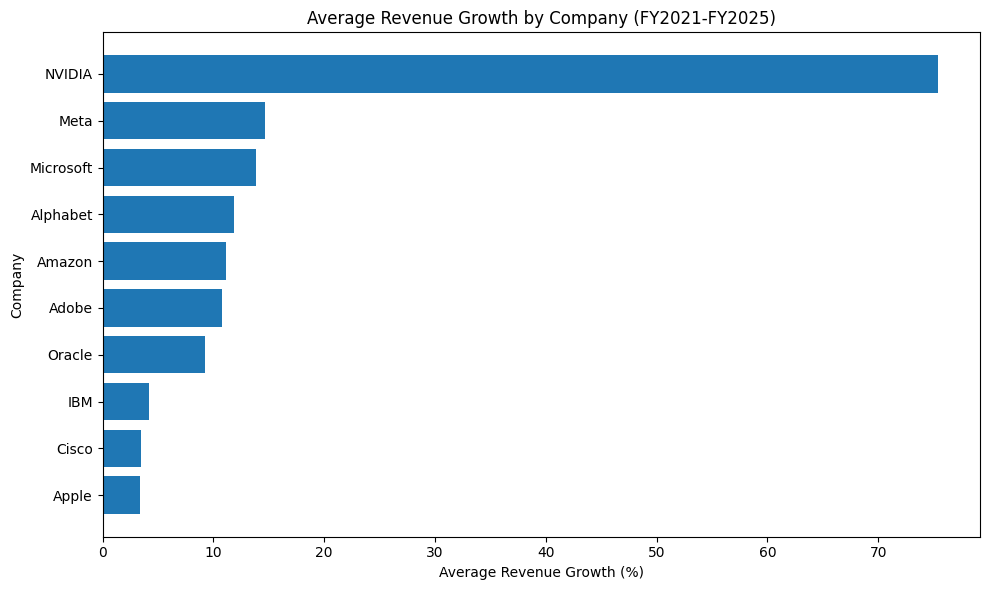

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    growth_chart_data["company"],
    growth_chart_data["avg_revenue_growth_pct"]
)

plt.xlabel("Average Revenue Growth (%)")
plt.ylabel("Company")
plt.title("Average Revenue Growth by Company (FY2021-FY2025)")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
# Step 24: Average Net Profit Margin by Company

margin_chart_data = (
    company_summary[
        [
            "company",
            "avg_net_profit_margin_pct"
        ]
    ]
    .sort_values(
        "avg_net_profit_margin_pct",
        ascending=False
    )
)

print("=" * 70)
print("AVERAGE NET PROFIT MARGIN — FY2021-FY2025")
print("=" * 70)

display(margin_chart_data)

AVERAGE NET PROFIT MARGIN — FY2021-FY2025


,company,avg_net_profit_margin_pct
8,NVIDIA,36.62
7,Microsoft,35.88
6,Meta,30.05
0,Adobe,28.28
1,Alphabet,27.23
3,Apple,25.48
9,Oracle,21.65
4,Cisco,20.69
5,IBM,10.03
2,Amazon,6.40


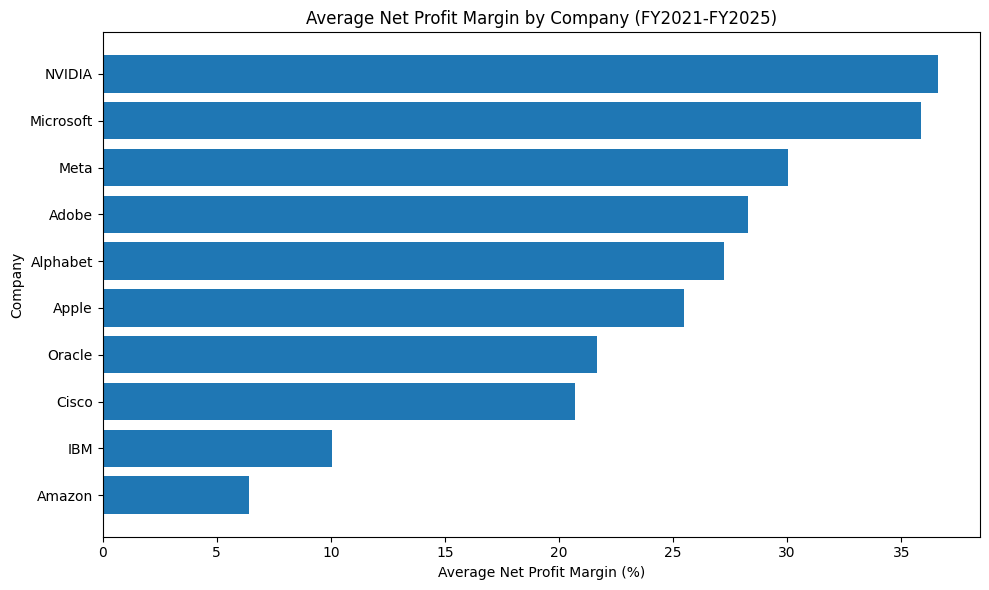

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    margin_chart_data["company"],
    margin_chart_data["avg_net_profit_margin_pct"]
)

plt.xlabel("Average Net Profit Margin (%)")
plt.ylabel("Company")
plt.title("Average Net Profit Margin by Company (FY2021-FY2025)")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
# Step 26: Average ROA by Company

roa_chart_data = (
    company_summary[
        [
            "company",
            "avg_roa_pct"
        ]
    ]
    .sort_values(
        "avg_roa_pct",
        ascending=False
    )
)

print("=" * 70)
print("AVERAGE ROA — FY2021-FY2025")
print("=" * 70)

display(roa_chart_data)

AVERAGE ROA — FY2021-FY2025


,company,avg_roa_pct
8,NVIDIA,31.66
3,Apple,27.93
1,Alphabet,20.07
0,Adobe,19.20
6,Meta,18.47
7,Microsoft,17.90
4,Cisco,10.49
9,Oracle,7.55
2,Amazon,6.42
5,IBM,4.51


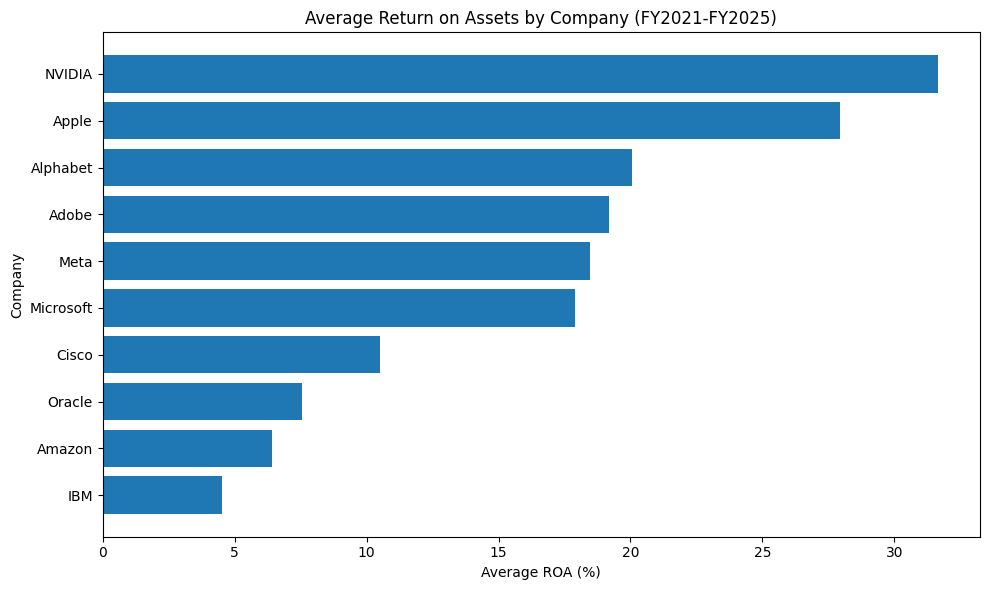

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    roa_chart_data["company"],
    roa_chart_data["avg_roa_pct"]
)

plt.xlabel("Average ROA (%)")
plt.ylabel("Company")
plt.title("Average Return on Assets by Company (FY2021-FY2025)")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
# Step 28: Average Liability-to-Asset Ratio by Company

liability_chart_data = (
    company_summary[
        [
            "company",
            "avg_liability_to_asset_pct"
        ]
    ]
    .sort_values(
        "avg_liability_to_asset_pct",
        ascending=False
    )
)

print("=" * 70)
print("AVERAGE LIABILITY-TO-ASSET RATIO — FY2021-FY2025")
print("=" * 70)

display(liability_chart_data)

AVERAGE LIABILITY-TO-ASSET RATIO — FY2021-FY2025


,company,avg_liability_to_asset_pct
9,Oracle,96.52
3,Apple,82.78
5,IBM,82.01
2,Amazon,60.26
4,Cisco,59.39
7,Microsoft,50.77
0,Adobe,50.48
8,NVIDIA,38.19
6,Meta,32.97
1,Alphabet,29.49


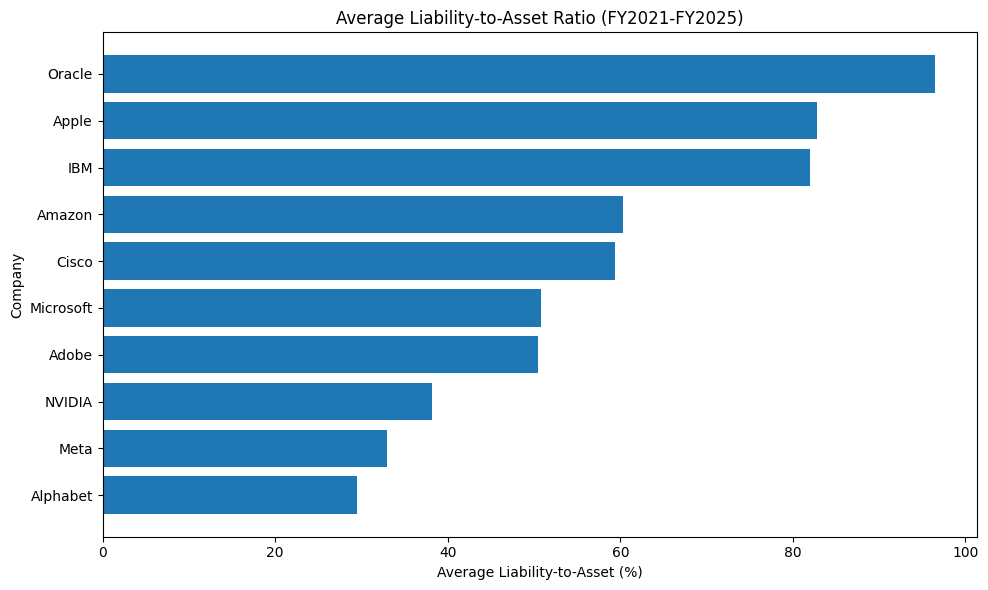

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    liability_chart_data["company"],
    liability_chart_data["avg_liability_to_asset_pct"]
)

plt.xlabel("Average Liability-to-Asset (%)")
plt.ylabel("Company")
plt.title("Average Liability-to-Asset Ratio (FY2021-FY2025)")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
# Step 30: Prepare revenue trend data

revenue_trend = (
    master_df[
        [
            "company",
            "fiscal_year",
            "revenue"
        ]
    ]
    .sort_values(
        ["fiscal_year", "company"]
    )
)

print("=" * 70)
print("REVENUE TREND — FY2021-FY2025")
print("=" * 70)

display(revenue_trend.head(15))

REVENUE TREND — FY2021-FY2025


,company,fiscal_year,revenue
0,Adobe,2021,15.785
5,Alphabet,2021,257.637
10,Amazon,2021,469.822
15,Apple,2021,365.817
20,Cisco,2021,49.818
25,IBM,2021,57.350
30,Meta,2021,117.929
35,Microsoft,2021,168.088
40,NVIDIA,2021,16.675
45,Oracle,2021,40.479


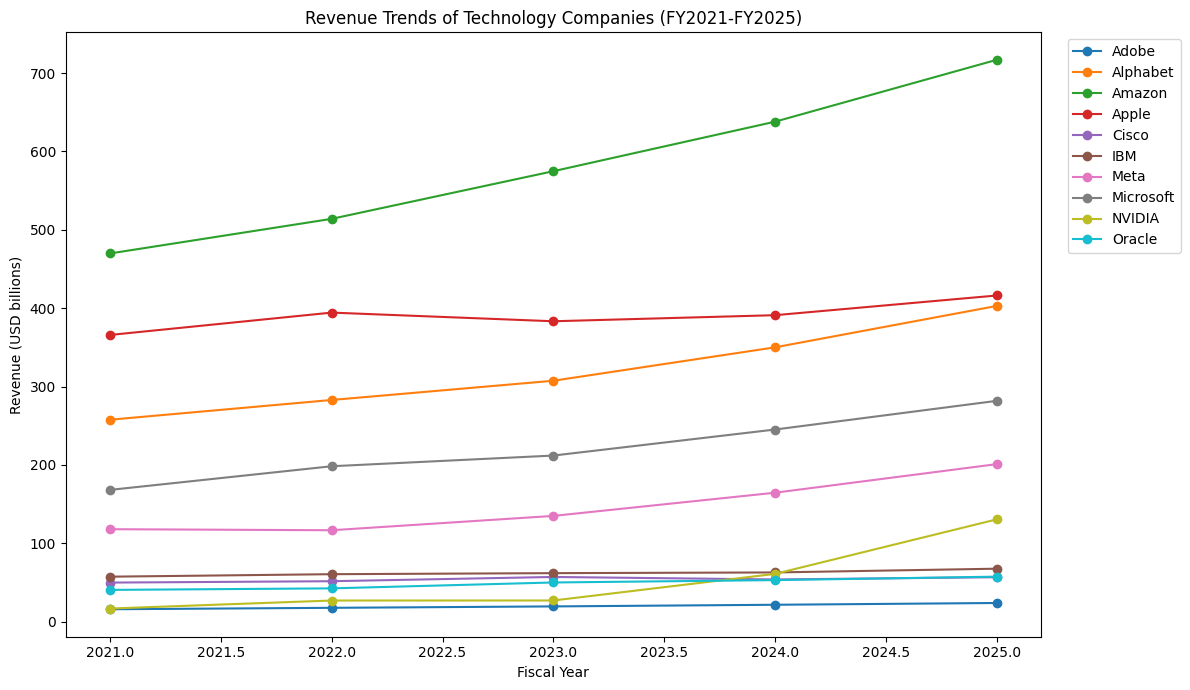

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

for company in revenue_trend["company"].unique():

    company_data = revenue_trend[
        revenue_trend["company"] == company
    ]

    plt.plot(
        company_data["fiscal_year"],
        company_data["revenue"],
        marker="o",
        label=company
    )

plt.xlabel("Fiscal Year")
plt.ylabel("Revenue (USD billions)")
plt.title("Revenue Trends of Technology Companies (FY2021-FY2025)")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [ ]:
# Step 32: Correlation analysis

correlation_columns = [
    "revenue_growth_pct",
    "net_profit_margin_pct",
    "roa_pct",
    "liability_to_asset_pct"
]

correlation_matrix = (
    master_df[correlation_columns]
    .corr()
    .round(2)
)

print("=" * 70)
print("CORRELATION MATRIX")
print("=" * 70)

display(correlation_matrix)

CORRELATION MATRIX


,revenue_growth_pct,net_profit_margin_pct,roa_pct,liability_to_asset_pct
revenue_growth_pct,1.00,0.66,0.73,-0.39
net_profit_margin_pct,0.66,1.00,0.81,-0.48
roa_pct,0.73,0.81,1.00,-0.41
liability_to_asset_pct,-0.39,-0.48,-0.41,1.00


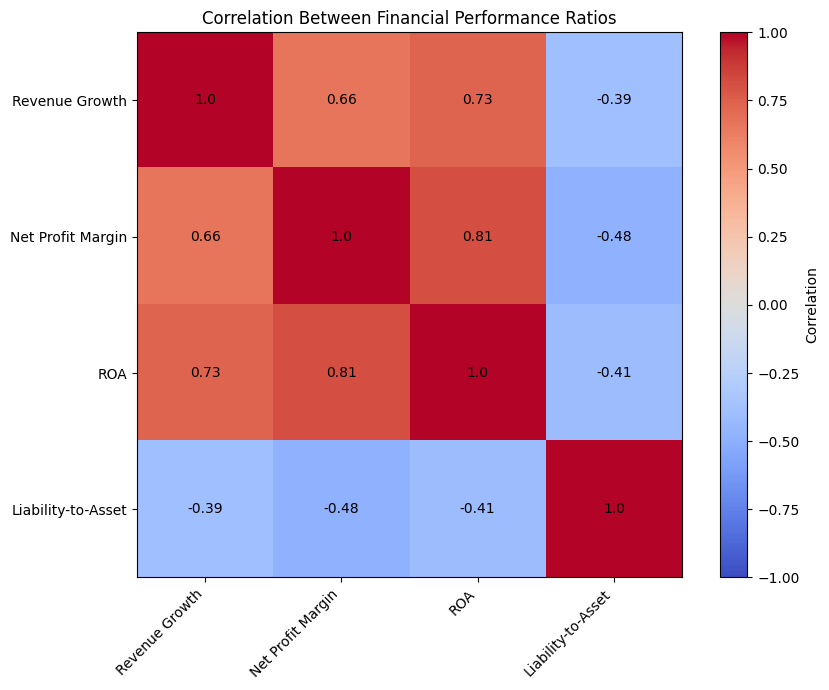

In [ ]:
# Step 33: Correlation heatmap

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    [
        "Revenue Growth",
        "Net Profit Margin",
        "ROA",
        "Liability-to-Asset"
    ],
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.index)),
    [
        "Revenue Growth",
        "Net Profit Margin",
        "ROA",
        "Liability-to-Asset"
    ]
)

for i in range(len(correlation_matrix.index)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j,
            i,
            correlation_matrix.iloc[i, j],
            ha="center",
            va="center"
        )

plt.title("Correlation Between Financial Performance Ratios")

plt.tight_layout()
plt.show()

In [ ]:
# Step 34: Export the final financial dataset

final_dataset = master_df.copy()

final_dataset.to_csv(
    "technology_companies_financial_analysis_2021_2025.csv",
    index=False
)

print("=" * 70)
print("FINAL DATASET EXPORTED")
print("=" * 70)

print("File name:")
print("technology_companies_financial_analysis_2021_2025.csv")

print("\nDataset shape:", final_dataset.shape)

print("\nColumns:")
print(final_dataset.columns.tolist())

FINAL DATASET EXPORTED
File name:
technology_companies_financial_analysis_2021_2025.csv

Dataset shape: (50, 11)

Columns:
['company', 'ticker', 'fiscal_year', 'revenue', 'net_income', 'total_assets', 'total_liabilities', 'revenue_growth_pct', 'net_profit_margin_pct', 'roa_pct', 'liability_to_asset_pct']


In [ ]:
# SQL Step 1: Create a SQLite database and load the final dataset

import sqlite3
import pandas as pd

# Create SQLite database
conn = sqlite3.connect("technology_financial_analysis.db")

# Load the CSV
sql_df = pd.read_csv(
    "technology_companies_financial_analysis_2021_2025.csv"
)

# Create SQL table
sql_df.to_sql(
    "financial_data",
    conn,
    if_exists="replace",
    index=False
)

print("=" * 70)
print("SQL DATABASE CREATED")
print("=" * 70)

print("Table name: financial_data")
print("Rows:", len(sql_df))
print("Columns:", len(sql_df.columns))

print("\nTable columns:")
print(sql_df.columns.tolist())

SQL DATABASE CREATED
Table name: financial_data
Rows: 50
Columns: 11

Table columns:
['company', 'ticker', 'fiscal_year', 'revenue', 'net_income', 'total_assets', 'total_liabilities', 'revenue_growth_pct', 'net_profit_margin_pct', 'roa_pct', 'liability_to_asset_pct']


In [ ]:
# SQL Query 1: Total revenue by company

query_1 = """
SELECT
    company,
    ROUND(SUM(revenue), 2) AS total_revenue
FROM financial_data
GROUP BY company
ORDER BY total_revenue DESC;
"""

result_1 = pd.read_sql_query(
    query_1,
    conn
)

display(result_1)

,company,total_revenue
0,Amazon,2913.47
1,Apple,1950.63
2,Alphabet,1600.72
3,Microsoft,1105.12
4,Meta,734.91
5,IBM,310.03
6,Cisco,268.83
7,NVIDIA,261.98
8,Oracle,243.23
9,Adobe,98.07


In [ ]:
# SQL Query 2: Average net profit margin by company

query_2 = """
SELECT
    company,
    ROUND(AVG(net_profit_margin_pct), 2) AS avg_net_profit_margin
FROM financial_data
GROUP BY company
ORDER BY avg_net_profit_margin DESC;
"""

result_2 = pd.read_sql_query(
    query_2,
    conn
)

display(result_2)

,company,avg_net_profit_margin
0,NVIDIA,36.62
1,Microsoft,35.88
2,Meta,30.05
3,Adobe,28.28
4,Alphabet,27.23
5,Apple,25.48
6,Oracle,21.65
7,Cisco,20.69
8,IBM,10.03
9,Amazon,6.40


In [ ]:
# SQL Query 3: Highest ROA observation

query_3 = """
SELECT
    company,
    fiscal_year,
    ROUND(roa_pct, 2) AS roa_pct
FROM financial_data
WHERE roa_pct = (
    SELECT MAX(roa_pct)
    FROM financial_data
);
"""

result_3 = pd.read_sql_query(
    query_3,
    conn
)

display(result_3)

,company,fiscal_year,roa_pct
0,NVIDIA,2025,65.3


In [ ]:
# SQL Query 4: Year-over-Year revenue using LAG()

query_4 = """
SELECT
    company,
    fiscal_year,
    ROUND(revenue, 2) AS revenue,
    ROUND(
        LAG(revenue) OVER (
            PARTITION BY company
            ORDER BY fiscal_year
        ),
        2
    ) AS previous_year_revenue,
    ROUND(
        revenue - LAG(revenue) OVER (
            PARTITION BY company
            ORDER BY fiscal_year
        ),
        2
    ) AS revenue_change
FROM financial_data
ORDER BY company, fiscal_year;
"""

result_4 = pd.read_sql_query(
    query_4,
    conn
)

display(result_4.head(20))

,company,fiscal_year,revenue,previous_year_revenue,revenue_change
0,Adobe,2021,15.79,NaN,NaN
1,Adobe,2022,17.61,15.79,1.82
2,Adobe,2023,19.41,17.61,1.80
3,Adobe,2024,21.50,19.41,2.10
4,Adobe,2025,23.77,21.50,2.26
5,Alphabet,2021,257.64,NaN,NaN
6,Alphabet,2022,282.84,257.64,25.20
7,Alphabet,2023,307.39,282.84,24.56
8,Alphabet,2024,350.02,307.39,42.62
9,Alphabet,2025,402.84,350.02,52.82


In [ ]:
# SQL Query 5: Company-year observations with net profit margin above 30%

query_5 = """
SELECT
    company,
    fiscal_year,
    ROUND(net_profit_margin_pct, 2) AS net_profit_margin
FROM financial_data
WHERE net_profit_margin_pct > 30
ORDER BY net_profit_margin DESC;
"""

result_5 = pd.read_sql_query(
    query_5,
    conn
)

display(result_5)

,company,fiscal_year,net_profit_margin
0,NVIDIA,2025,55.85
1,NVIDIA,2024,48.85
2,Meta,2024,37.91
3,Microsoft,2022,36.69
4,Microsoft,2021,36.45
5,NVIDIA,2022,36.23
6,Microsoft,2025,36.15
7,Microsoft,2024,35.96
8,Microsoft,2023,34.15
9,Oracle,2021,33.96


In [ ]:
# SQL Query 6: Strong profitability observations

query_6 = """
SELECT
    company,
    fiscal_year,
    ROUND(revenue, 2) AS revenue,
    ROUND(net_profit_margin_pct, 2) AS net_profit_margin,
    ROUND(roa_pct, 2) AS roa,
    ROUND(liability_to_asset_pct, 2) AS liability_to_asset
FROM financial_data
WHERE net_profit_margin_pct > 25
  AND roa_pct > 20
ORDER BY roa DESC;
"""

result_6 = pd.read_sql_query(
    query_6,
    conn
)

display(result_6)

,company,fiscal_year,revenue,net_profit_margin,roa,liability_to_asset
0,NVIDIA,2025,130.50,55.85,65.30,28.92
1,NVIDIA,2024,60.92,48.85,45.28,34.61
2,Apple,2025,416.16,26.92,31.18,79.48
3,Apple,2022,394.33,25.31,28.29,85.64
4,Apple,2023,383.29,25.31,27.51,82.37
5,Apple,2021,365.82,25.88,26.97,82.03
6,Adobe,2025,23.77,30.00,24.17,60.59
7,Meta,2021,117.93,33.38,23.72,24.77
8,Meta,2024,164.50,37.91,22.59,33.84
9,Alphabet,2024,350.02,28.60,22.24,27.80


In [ ]:
from google.colab import files

files.download("technology_companies_financial_analysis_2021_2025.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>